In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0][:20])
print("First label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First label: 1


In [ ]:
X_train = pad_sequences(
    X_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [ ]:
embedding_dim = 64
hidden_units = 64

def create_rnn_model():
    model = Sequential([
        Embedding(vocab_size, embedding_dim, mask_zero=True),
        SimpleRNN(hidden_units),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def create_lstm_model():
    model = Sequential([
        Embedding(vocab_size, embedding_dim, mask_zero=True),
        LSTM(hidden_units),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


def create_gru_model():
    model = Sequential([
        Embedding(vocab_size, embedding_dim, mask_zero=True),
        GRU(hidden_units),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [ ]:
models = {
    "RNN": create_rnn_model(),
    "LSTM": create_lstm_model(),
    "GRU": create_gru_model()
}

for name, model in models.items():
    print("\n", name, "Model Summary")
    model.summary()


 RNN Model Summary


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
start_time = time.time()

rnn_history = models["RNN"].fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

rnn_time = time.time() - start_time

print("RNN Training Time:", round(rnn_time, 2), "seconds")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 33s 96ms/step - accuracy: 0.5364 - loss: 0.6921 - val_accuracy: 0.6110 - val_loss: 0.6713
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.6442 - loss: 0.6405 - val_accuracy: 0.5580 - val_loss: 0.6883
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 29s 92ms/step - accuracy: 0.8072 - loss: 0.4341 - val_accuracy: 0.6002 - val_loss: 0.7624
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 92ms/step - accuracy: 0.9493 - loss: 0.1489 - val_accuracy: 0.6814 - val_loss: 0.7623
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 97ms/step - accuracy: 0.9926 - loss: 0.0363 - val_accuracy: 0.6912 - val_loss: 0.9448
RNN Training Time: 172.39 seconds


In [ ]:
start_time = time.time()

lstm_history = models["LSTM"].fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

lstm_time = time.time() - start_time

print("LSTM Training Time:", round(lstm_time, 2), "seconds")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 59s 177ms/step - accuracy: 0.7541 - loss: 0.4971 - val_accuracy: 0.8214 - val_loss: 0.4014
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 183ms/step - accuracy: 0.8840 - loss: 0.2973 - val_accuracy: 0.8574 - val_loss: 0.3351
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 184ms/step - accuracy: 0.9179 - loss: 0.2219 - val_accuracy: 0.8556 - val_loss: 0.3372
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 177ms/step - accuracy: 0.9396 - loss: 0.1665 - val_accuracy: 0.8546 - val_loss: 0.4323
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 178ms/step - accuracy: 0.9549 - loss: 0.1271 - val_accuracy: 0.8508 - val_loss: 0.4516
LSTM Training Time: 311.22 seconds


In [ ]:
start_time = time.time()

gru_history = models["GRU"].fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

gru_time = time.time() - start_time

print("GRU Training Time:", round(gru_time, 2), "seconds")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 62s 188ms/step - accuracy: 0.6906 - loss: 0.5803 - val_accuracy: 0.8266 - val_loss: 0.4002
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 58s 185ms/step - accuracy: 0.8708 - loss: 0.3195 - val_accuracy: 0.8388 - val_loss: 0.4199
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 189ms/step - accuracy: 0.9115 - loss: 0.2408 - val_accuracy: 0.8648 - val_loss: 0.3379
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 186ms/step - accuracy: 0.9338 - loss: 0.1848 - val_accuracy: 0.8614 - val_loss: 0.3638
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 61s 196ms/step - accuracy: 0.9571 - loss: 0.1287 - val_accuracy: 0.8512 - val_loss: 0.4035
GRU Training Time: 345.14 seconds


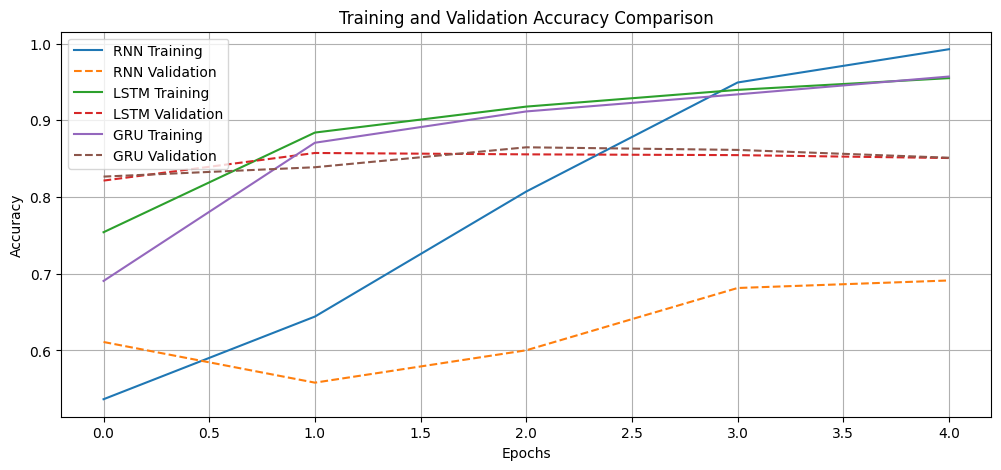

In [ ]:
histories = {
    "RNN": rnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

plt.figure(figsize=(12, 5))

for name, history in histories.items():
    plt.plot(history.history['accuracy'], label=name + ' Training')
    plt.plot(history.history['val_accuracy'], linestyle='--',
             label=name + ' Validation')

plt.title("Training and Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

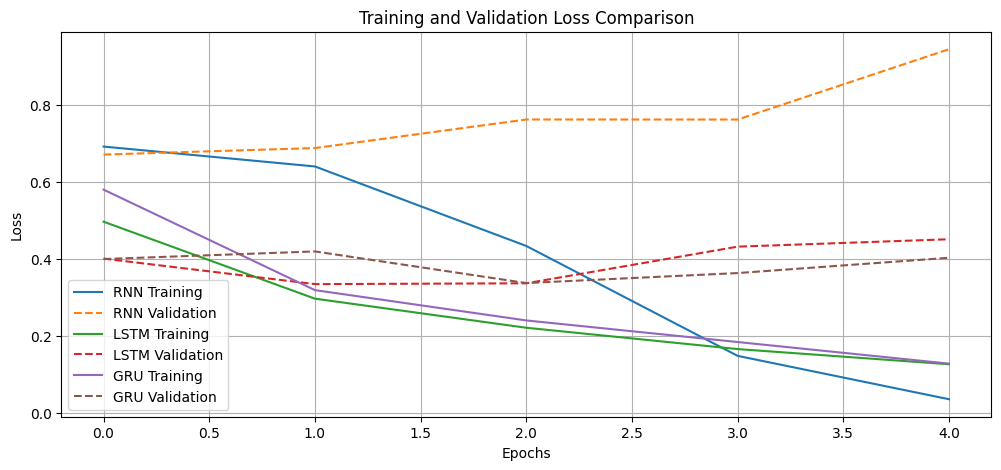

In [ ]:
plt.figure(figsize=(12, 5))

for name, history in histories.items():
    plt.plot(history.history['loss'], label=name + ' Training')
    plt.plot(history.history['val_loss'], linestyle='--',
             label=name + ' Validation')

plt.title("Training and Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [ ]:
results = {}

training_times = {
    "RNN": rnn_time,
    "LSTM": lstm_time,
    "GRU": gru_time
}

for name, model in models.items():

    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "Training Time (sec)": training_times[name]
    }

    print("\n", name, "Classification Report")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))


 RNN Classification Report
              precision    recall  f1-score   support

    Negative       0.67      0.68      0.68     12500
    Positive       0.68      0.67      0.67     12500

    accuracy                           0.67     25000
   macro avg       0.67      0.67      0.67     25000
weighted avg       0.67      0.67      0.67     25000


 LSTM Classification Report
              precision    recall  f1-score   support

    Negative       0.86      0.80      0.83     12500
    Positive       0.81      0.87      0.84     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84     25000
weighted avg       0.84      0.84      0.84     25000


 GRU Classification Report
              precision    recall  f1-score   support

    Negative       0.86      0.81      0.83     12500
    Positive       0.82      0.86      0.84     12500

    accuracy                           0.84     25000
   macro avg       0.84      0.84      0.84

In [ ]:
comparison_df = pd.DataFrame(results).T

print("Performance Comparison of RNN, LSTM and GRU")
display(comparison_df.round(4))

Performance Comparison of RNN, LSTM and GRU


,Accuracy,Precision,Recall,F1 Score,Training Time (sec)
RNN,0.6747,0.6752,0.6733,0.6743,172.387
LSTM,0.8359,0.8149,0.8693,0.8412,311.219
GRU,0.8389,0.8227,0.8639,0.8428,345.143


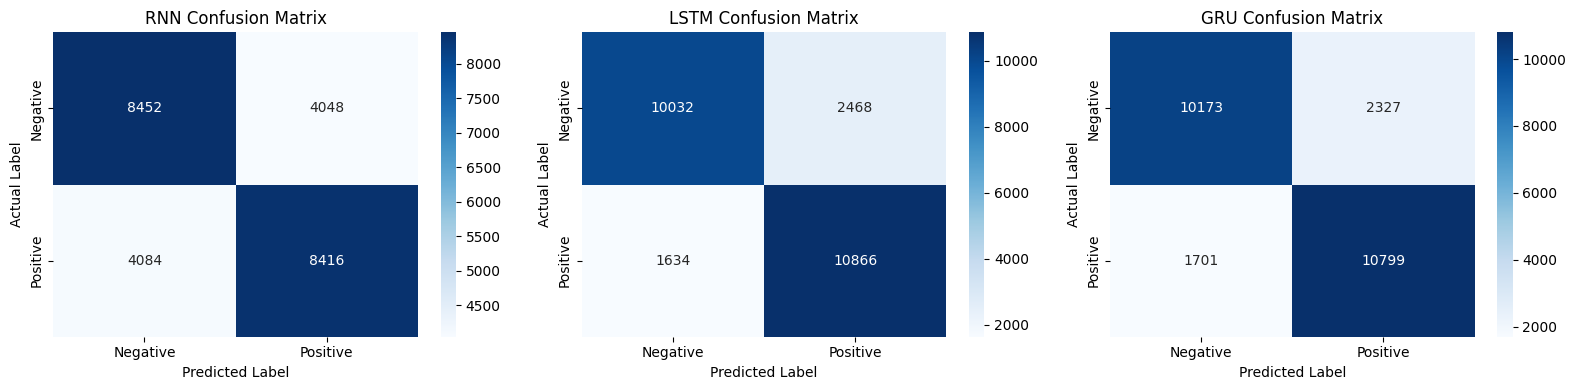

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, model) in zip(axes, models.items()):

    y_pred = (model.predict(X_test, verbose=0) >= 0.5).astype(int)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive'],
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

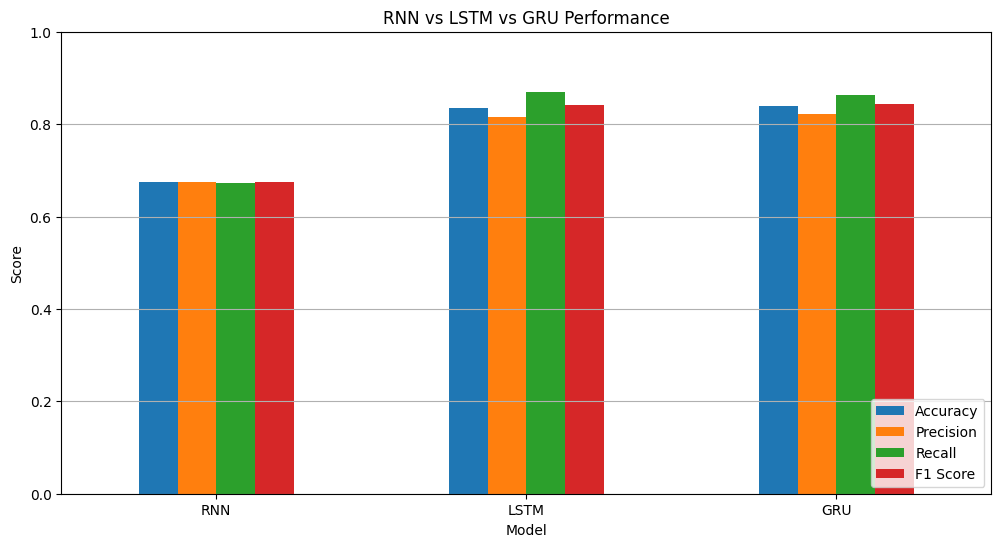

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_df[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y')
plt.show()

In [ ]:
best_model = comparison_df["F1 Score"].idxmax()

print("Best Performing Model:", best_model)
print("Best F1 Score:", round(comparison_df.loc[best_model, "F1 Score"], 4))

fastest_model = comparison_df["Training Time (sec)"].idxmin()

print("Fastest Model:", fastest_model)
print(
    "Training Time:",
    round(comparison_df.loc[fastest_model, "Training Time (sec)"], 2),
    "seconds"
)

Best Performing Model: GRU
Best F1 Score: 0.8428
Fastest Model: RNN
Training Time: 172.39 seconds


In [ ]:
print("CONCLUSION")
print("-" * 60)

for name in models.keys():
    print(
        f"{name}: "
        f"Accuracy = {results[name]['Accuracy']:.4f}, "
        f"Precision = {results[name]['Precision']:.4f}, "
        f"Recall = {results[name]['Recall']:.4f}, "
        f"F1 Score = {results[name]['F1 Score']:.4f}, "
        f"Training Time = {results[name]['Training Time (sec)']:.2f}s"
    )

print("\nBest Model based on F1 Score:", best_model)
print("Fastest Model:", fastest_model)

CONCLUSION
------------------------------------------------------------
RNN: Accuracy = 0.6747, Precision = 0.6752, Recall = 0.6733, F1 Score = 0.6743, Training Time = 172.39s
LSTM: Accuracy = 0.8359, Precision = 0.8149, Recall = 0.8693, F1 Score = 0.8412, Training Time = 311.22s
GRU: Accuracy = 0.8389, Precision = 0.8227, Recall = 0.8639, F1 Score = 0.8428, Training Time = 345.14s

Best Model based on F1 Score: GRU
Fastest Model: RNN
